# Этап 12. Проверка вклада графа и заключительная диагностика модели

**Цель.** Завершить методологические проверки экономической типологии. 

**Уже установлено.** Для 2016 муниципалитетов за 24 месяца отобран Temporal K-Means: четыре типа, месячные CLR-атрибуты, union kNN с $k=10$, $\beta=0{,}15$, $\lambda=0{,}25$. Этап 11 показал высокую медианную устойчивость по seed, но отдельные месяцы менее устойчивы. Этап 10 предложил экономическую интерпретацию типов по БДМО.

На этом этапе проверяем: (1) влияет ли *сам графовый штраф* на разбиение; (2) сохраняется ли эффект при небольших изменениях $\beta$; (3) где находятся нестабильные месяцы и неоднозначные муниципалитеты; (4) не является ли устойчивость следствием подавления содержательных изменений; (5) сохраняется ли внешний экономический смысл

## 1. Математическая постановка и проверяемые гипотезы

Для фиксированных CLR-признаков $x_{it}$, графа $A_t$ и месячных прототипов $c_{at}$ рассматриваем стоимость назначения типа $a$:

$$
U_{it}^{(\beta)}(a)
=\frac{\lVert x_{it}-c_{at}\rVert_2^2}{s}
+\beta\left(1-\frac{\sum_j A_{ij,t}\mathbf{1}[g^{\mathrm{ref}}_{jt}=a]}{\sum_j A_{ij,t}}\right).
$$

Здесь $s$ — медиана положительных внутрикластерных квадратов расстояний из функции `run_lambda_grid`; $g^{\mathrm{ref}}$ — **фиксированные** согласованные метки K-Means этапа 07. При нулевой силе узла в графе доля соседей определяется как ноль в реализации. Слагаемое с $\beta$ не является новым независимым источником данных: граф построен из тех же CLR-признаков. Оно выражает способ структурной регуляризации.

Временная модель минимизирует по траекториям $g_{it}$:

$$
\mathcal L_{\beta,\lambda}(g)=\sum_{i,t}U_{it}^{(\beta)}(g_{it})
+\lambda\sum_{i,t>1}\mathbf{1}[g_{it}\neq g_{i,t-1}].
$$

Сравниваем $\beta\in\{0;0{,}05;0{,}15;0{,}30\}$ при **одинаковых** центрах, графах, $\lambda=0{,}25$, 2016 муниципалитетах и 24 месяцах. Главное сравнение — $\beta=0$ против $\beta=0{,}15$. Дополнительные точки проверяют чувствительность, а не служат новым подбором оптимума. $\beta=0$ отключает только графовую добавку: временная регуляризация остаётся включённой.

**Нулевая гипотеза диагностического эксперимента:** графовый штраф практически не меняет разбиения или подтверждённые характеристики качества. Противоположный результат указывает на алгоритмический вклад графа, но сам по себе не доказывает независимую экономическую информацию, причинную связь или прогнозную пригодность.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score, calinski_harabasz_score

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_analysis import parse_dynamic_columns
from src.cluster_models import read_graph_sequence
from src.temporal_analysis import raw_labels, align_history, features_by_month
from src.model_robustness import (
    graph_ablation_paths, graph_ablation_monthly, graph_ablation_changes,
    unstable_seed_diagnostics, temporal_kmeans_repeat, seed_repeatability,
    annual_expost_separation, validate_candidate
)

cfg = json.loads((ROOT / 'configs/clustering_experiment.json').read_text(encoding='utf-8'))
acfg, tcfg = cfg['graph_ablation_12'], cfg['temporal_08']
X_dynamic = pd.read_parquet(ROOT / cfg['feature_path'])
mapping = parse_dynamic_columns(X_dynamic)
months = [str(m) for m in sorted({m for m, _ in mapping})]
assert len(months) == 24 and X_dynamic.index.is_unique and len(X_dynamic) == 2016
features = features_by_month(X_dynamic, mapping, months, cfg['zero_floor'])
graph_dir = ROOT / cfg['graph_directory']
manifest = json.loads((graph_dir / 'manifest.json').read_text(encoding='utf-8'))
expected = {'method': 'union', 'representation': 'clr', 'window': 1, 'k': 10}
if any(manifest.get(key) != value for key, value in expected.items()):
    raise ValueError('Манифест графов не соответствует выбранной сети этапа 06')
graphs = read_graph_sequence(graph_dir, X_dynamic.index, months)

saved_dir = ROOT / acfg['reference_final_directory']
if not (saved_dir / 'final_labels.parquet').exists():
    raise FileNotFoundError('Сначала выполните последнюю ячейку шага 11: отсутствует final_labels.parquet')
final_meta = json.loads((saved_dir / 'final_model.json').read_text(encoding='utf-8'))
if final_meta.get('selected_configuration') != 'temporal_clr_k10_lambda_0.25':
    raise ValueError('Итоговая конфигурация шага 11 отличается от ожидаемой')
base = pd.read_parquet(saved_dir / 'final_labels.parquet')
if not base.index.equals(X_dynamic.index) or list(base.columns) != months:
    raise ValueError('Итоговые метки этапа 11 не совпадают с муниципалитетами или месяцами')

labels07 = pd.read_parquet(ROOT / cfg['output_directory'] / 'labels.parquet')
if not labels07.index.equals(X_dynamic.index):
    raise ValueError('Индекс меток этапа 07 отличается от индекса муниципалитетов')
reference, _ = align_history(
    raw_labels(labels07, months, 'kmeans'),
    min_jaccard=tcfg['matching_min_jaccard'],
    event_fraction=tcfg['event_min_fraction'],
    min_event_size=tcfg['event_min_size']
)
validate_candidate(reference, base)
assert np.isclose(acfg['lambda_fixed'], tcfg['selection'])
assert np.isclose(tcfg['graph_beta'], acfg['primary_comparison'][1])
print(f'Муниципалитетов: {len(X_dynamic)}; месяцев: {len(months)}; графы: {manifest["method"]}, k={manifest["k"]}')
print('Сохранённая финальная модель:', final_meta['selected_configuration'])

Муниципалитетов: 2016; месяцев: 24; графы: union, k=10
Сохранённая финальная модель: temporal_clr_k10_lambda_0.25


## 2. Контролируемый графовый эксперимент

Все четыре варианта используют один `reference` и одну последовательность графов. Функция из `src/model_robustness.py` повторно применяет только временную оптимизацию Витерби; алгоритмы K-Means, Spectral и Leiden **не переобучаются**.

Проверка воспроизводимости: результат $\beta=0{,}15$ обязан совпасть с `final_labels.parquet` этапа 11 (ARI = 1 за каждый месяц). При несовпадении расчёты останавливаются, поскольку вывод о влиянии графа был бы некорректен.

**Замечание:** значение `emission_cost` зависит от β, поскольку β входит в саму функцию стоимости. Сравнивать абсолютные потери между разными β напрямую нельзя; используем независимые ARI/NMI, модулярность, геометрическое качество и экономический контекст.

In [2]:
beta_paths, ablation_objective = graph_ablation_paths(
    reference, features, graphs, acfg['beta_values'], acfg['lambda_fixed']
)
selected_beta = float(tcfg['graph_beta'])
control_beta = 0.0
for beta in (control_beta, selected_beta):
    assert beta in beta_paths
verification = [adjusted_rand_score(base[m], beta_paths[selected_beta][m]) for m in months]
if min(verification) < 1 - 1e-10:
    raise ValueError('β=0,15 не воспроизводит сохранённые метки этапа 11')
print('Минимальный ARI повторного воспроизведения:', round(min(verification), 6))
display(ablation_objective[[
    'graph_beta', 'modularity_median',
    'ari_adjacent_median', 'switch_share_median',
    'ari_to_independent_median'
]].round(4))

Минимальный ARI повторного воспроизведения: 1.0


,graph_beta,modularity_median,ari_adjacent_median,switch_share_median,ari_to_independent_median
0,0.00,0.6363,0.8585,0.0565,0.9517
1,0.05,0.6366,0.8558,0.0585,0.9531
2,0.15,0.6369,0.8480,0.0590,0.9552
3,0.30,0.6381,0.8439,0.0620,0.9560


## 3. Масштаб изменения разбиения при отключении графа

Для $\beta$ сравним каждый месяц с контролем $\beta=0$:

$$
C_t(\beta)=\frac1N\sum_{i=1}^N
\mathbf{1}[g_{it}^{(\beta)}\neq g_{it}^{(0)}],
$$

где $C_t$ — доля изменивших **согласованный идентификатор** типа. Дополнительно используем ARI и NMI, не зависящие от перестановки номеров. Модулярность всех решений вычисляется на **одном и том же** графе $A_t$; отдельно контролируем долю крупнейшего кластера и число непустых кластеров.

Осторожность: из-за совпадения меток $C_t$ можно интерпретировать напрямую. Для независимых несопоставленных разбиений так делать нельзя.

In [3]:
monthly_effect = graph_ablation_monthly(reference, beta_paths, graphs)
summary = monthly_effect.groupby('beta', as_index=False).agg(
    ari_median=('ari_to_beta0', 'median'), ari_min=('ari_to_beta0', 'min'),
    nmi_median=('nmi_to_beta0', 'median'),
    changed_median=('changed_share_to_beta0', 'median'),
    changed_max=('changed_share_to_beta0', 'max'),
    changed_total=('changed_count_to_beta0', 'sum'),
    modularity_median=('modularity_same_graph', 'median'),
    largest_share_median=('largest_cluster_share', 'median'),
    clusters_min=('clusters', 'min')
)
display(summary.round(4))
print('Пять месяцев с наибольшими изменениями при β=0,15:')
display(monthly_effect.query('beta == @selected_beta')
    .nlargest(5, 'changed_share_to_beta0')
    [['month','ari_to_beta0','changed_share_to_beta0','modularity_same_graph']]
    .round(4))

,beta,ari_median,ari_min,nmi_median,changed_median,changed_max,changed_total,modularity_median,largest_share_median,clusters_min
0,0.00,1.0000,1.0000,1.0000,0.0000,0.0000,0,0.6363,0.3348,4
1,0.05,0.9973,0.9913,0.9947,0.0010,0.0030,60,0.6366,0.3343,4
2,0.15,0.9912,0.9758,0.9835,0.0032,0.0084,176,0.6369,0.3351,4
3,0.30,0.9845,0.9661,0.9717,0.0057,0.0119,305,0.6381,0.3351,4


Пять месяцев с наибольшими изменениями при β=0,15:


,month,ari_to_beta0,changed_share_to_beta0,modularity_same_graph
60,2024-01,0.9758,0.0084,0.6238
48,2023-01,0.9812,0.0074,0.6194
67,2024-08,0.9819,0.0064,0.6513
65,2024-06,0.9852,0.0055,0.6515
71,2024-12,0.9848,0.0055,0.6477


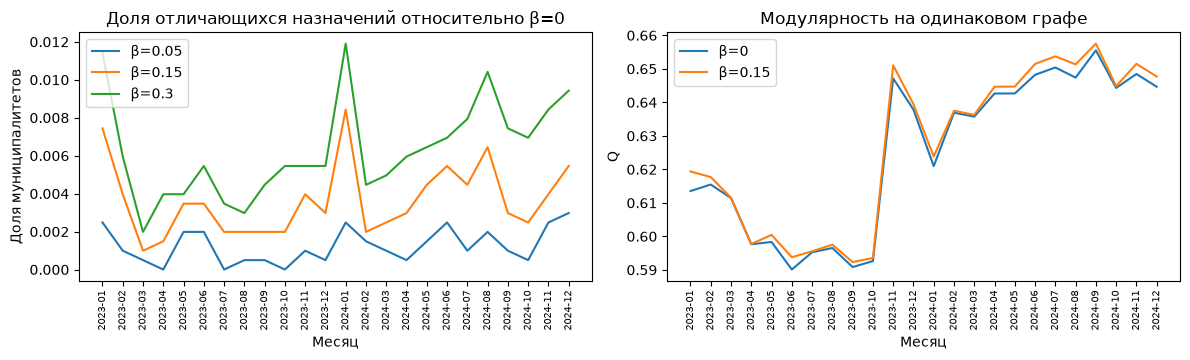

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
for beta in acfg['beta_values']:
    if beta == control_beta:
        continue
    block = monthly_effect[monthly_effect.beta.eq(beta)]
    axes[0].plot(block.month, block.changed_share_to_beta0, label=f'β={beta:g}')
axes[0].set(title='Доля отличающихся назначений относительно β=0', ylabel='Доля муниципалитетов', xlabel='Месяц')
axes[0].tick_params(axis='x', rotation=90, labelsize=7)
axes[0].legend()
for beta in (control_beta, selected_beta):
    block = monthly_effect[monthly_effect.beta.eq(beta)]
    axes[1].plot(block.month, block.modularity_same_graph, label=f'β={beta:g}')
axes[1].set(title='Модулярность на одинаковом графе', xlabel='Месяц', ylabel='Q')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Где возникала случайная нестабильность

Три `random_state` из этапа 11 повторяются только для основной модели. На каждой паре запусков оцениваются ARI и NMI; выделяем месяцы с минимальным ARI, а также доли муниципалитетов, у которых хотя бы два запуска расходятся в назначении типа.

Для интерпретации близости к границе используем нормированный отрыв двух ближайших месячных центроидов:

$$
M_{it}=\frac{d_{i,(2),t}^{2}-d_{i,(1),t}^{2}}
{d_{i,(2),t}^{2}+\varepsilon},\qquad \varepsilon=10^{-12}.
$$

Здесь $d_{i,(1),t}^{2}$ и $d_{i,(2),t}^{2}$ — минимальное и второе по величине расстояния до центров в CLR-пространстве. Малый $M_{it}$ означает геометрическую неоднозначность, но не доказывает причину различий между запусками временной модели.

In [5]:
seed_paths = {int(acfg['seeds'][0]): base}
for seed in acfg['seeds'][1:]:
    seed_paths[int(seed)] = temporal_kmeans_repeat(
        reference, features, graphs,
        int(cfg['selected_parameters']['kmeans']), int(seed),
        float(acfg['lambda_fixed']), selected_beta
    )
seed_pairs = seed_repeatability(seed_paths)
weak_months, weak_clusters = unstable_seed_diagnostics(seed_paths, reference, features)
count = int(acfg['top_unstable_months'])
weakest = weak_months.nsmallest(count, 'worst_pair_ari')
print('Случайная устойчивость на 72 сравнений «пара seed × месяц»:')
display(seed_pairs[['ari','nmi']].agg(['median','min']).round(4))
print('Проблемные месяцы и относительный CLR-отрыв:')
display(weakest.round(4))
print('Кластеры внутри проблемных месяцев:')
display(weak_clusters[weak_clusters.month.isin(weakest.month)]
        .sort_values(['month','disagreement_share'], ascending=[True,False])
        .round(4))

Случайная устойчивость на 72 сравнений «пара seed × месяц»:


,ari,nmi
median,0.9924,0.9868
min,0.4605,0.5731


Проблемные месяцы и относительный CLR-отрыв:


,month,worst_pair_ari,median_pair_ari,worst_pair_nmi,disagreement_share,median_margin_disagree,median_margin_agree
11,2023-12,0.4605,0.4704,0.5731,0.3224,0.5164,0.7354
10,2023-11,0.9349,0.9371,0.9220,0.0243,0.1491,0.6579
8,2023-09,0.9571,0.9647,0.9325,0.0218,0.0916,0.7378
12,2024-01,0.9592,0.9592,0.9491,0.0149,0.0969,0.7007
19,2024-08,0.9596,0.9640,0.9482,0.0159,0.1781,0.6790


Кластеры внутри проблемных месяцев:


,month,cluster,size,disagreement_share,median_margin_disagree,median_margin_agree
35,2023-09,3,121,0.0579,0.0404,0.5947
32,2023-09,0,718,0.0348,0.1523,0.6373
34,2023-09,2,627,0.0159,0.0455,0.7316
33,2023-09,1,550,0.0036,0.1421,0.8920
43,2023-11,3,514,0.0623,0.1815,0.5720
40,2023-11,0,666,0.0225,0.0856,0.5942
42,2023-11,2,387,0.0026,0.0029,0.6971
41,2023-11,1,449,0.0022,0.0452,0.8650
47,2023-12,3,553,0.8481,0.5942,0.2849
44,2023-12,0,646,0.2307,0.4273,0.6776


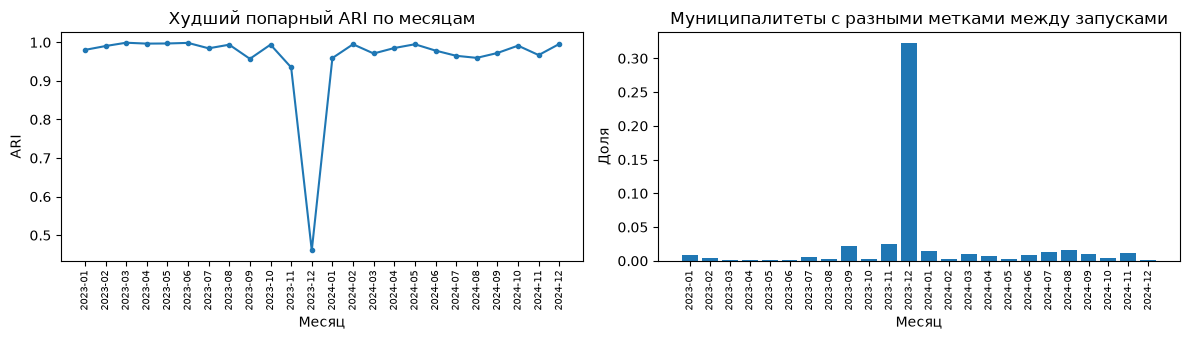

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(weak_months.month, weak_months.worst_pair_ari, marker='o', ms=3)
axes[0].set(title='Худший попарный ARI по месяцам', ylabel='ARI', xlabel='Месяц')
axes[0].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].bar(weak_months.month, weak_months.disagreement_share)
axes[1].set(title='Муниципалитеты с разными метками между запусками',
            ylabel='Доля', xlabel='Месяц')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
plt.tight_layout()
plt.show()

## 5. Реальные изменения и внешний экономический контекст

При оценке динамики не будем выбирать модель только по числу переключений. Для пары месяцев $t-1,t$ вычислим величину изменения CLR-признаков:

$$
\Delta_{it}=\lVert x_{it}-x_{i,t-1}\rVert_2.
$$

Затем отдельно найдём медианы $\Delta_{it}$ для муниципалитетов, сохранивших и сменивших тип. Снижение переходов при $\beta>0$ можно трактовать как улучшение, только если не исчезают изменения, поддержанные фактическими сдвигами признаков. Эти расчёты описательные и не измеряют причинную связь.

Внешняя проверка по восьми годовым показателям БДМО — ранговая межгрупповая $\eta^2$ за два декабрьских среза. Для каждого показателя используется своя доступная подвыборка: пропуски не заполняются. **Годовые значения 2024 года используются только ex post, не как признаки модели на декабрь 2024 года.**

In [7]:
transition_evidence = graph_ablation_changes(beta_paths, features)
display(transition_evidence.groupby('beta').agg(
    switch_median=('transition_share', 'median'),
    clr_change_switch=('clr_change_switch', 'median'),
    clr_change_stay=('clr_change_stay', 'median'),
    top_quartile_among_switches=('share_change_top_quartile_switch', 'median')
).round(4))

annual = pd.read_parquet(ROOT / cfg['annual_07a']['annual_path'])
if not annual.index.equals(X_dynamic.index):
    raise ValueError('X_annual имеет несовместимые ID или порядок')
external_rows = []
for snapshot, year in acfg['annual_snapshots']:
    pair = {f'beta_{beta:g}': beta_paths[float(beta)] for beta in acfg['primary_comparison']}
    part = annual_expost_separation(annual, pair, month=snapshot, year=int(year))
    part.insert(0, 'snapshot', snapshot)
    external_rows.append(part)
external = pd.concat(external_rows, ignore_index=True)
print('Внешнее разделение по БДМО:')
display(external.round(4))

,switch_median,clr_change_switch,clr_change_stay,top_quartile_among_switches
beta,,,,
0.00,0.0565,0.2421,0.1615,0.5190
0.05,0.0585,0.2405,0.1614,0.5225
0.15,0.0590,0.2415,0.1611,0.5133
0.30,0.0620,0.2405,0.1610,0.5085


Внешнее разделение по БДМО:


,snapshot,configuration,eta2_rank_median,valid_indicators,min_n_observed
0,2023-12,beta_0,0.1298,8,1876
1,2023-12,beta_0.15,0.1301,8,1876
2,2024-12,beta_0,0.1577,8,1840
3,2024-12,beta_0.15,0.1578,8,1840


## 6. Общее сравнение и критерии решения

Единая таблица объединяет **несмешиваемые** критерии: изменения назначений при добавлении графа, временные ARI и долю переходов, модулярность на общей сети, описательную проверку месячных изменений и ретроспективную связь с БДМО. SW и CH на четырёх фиксированных контрольных месяцах приводятся только как диагностический контроль в одной CLR-геометрии; это **не новый этап подбора ICVI**.

Существенное отличие между вариантами следует подтверждать одновременно размером эффекта, его повторяемостью в разных месяцах и экономическим смыслом. Незначительное изменение меток при $\beta=0{,}15$ означает, что граф помогает интерпретации или формализации соседства, но практически не влияет на данную кластеризацию. Максимальная временная стабильность сама по себе не является критерием победы.

In [8]:
pilot_months = [months[int(i)] for i in acfg['pilot_month_indices']]
geometry_rows = []
for beta in acfg['primary_comparison']:
    for month in pilot_months:
        lab = beta_paths[float(beta)][month].to_numpy()
        arr = features[month].to_numpy(float)
        valid = 1 < np.unique(lab).size < len(lab)
        geometry_rows.append({
            'beta': float(beta), 'month': month,
            'sw_full_clr': silhouette_score(arr, lab) if valid else np.nan,
            'ch_full_clr': calinski_harabasz_score(arr, lab) if valid else np.nan
        })
geometry = pd.DataFrame(geometry_rows)
geometry_summary = geometry.groupby('beta').agg(
    sw_pilot_median=('sw_full_clr','median'),
    ch_pilot_median=('ch_full_clr','median'),
    valid_months=('sw_full_clr','count')
)
changes_summary = transition_evidence.groupby('beta').agg(
    clr_change_switch_median=('clr_change_switch','median'),
    clr_change_stay_median=('clr_change_stay','median'),
    transition_share_median=('transition_share','median')
)
comparison = (summary.set_index('beta')
    .join(ablation_objective.set_index('graph_beta')[[
        'ari_adjacent_median','switch_share_median']])
    .join(changes_summary)
    .join(geometry_summary)
    .reset_index())
print('Сводка: все 24 месяца, SW/CH — 4 контрольных месяца:')
display(comparison.round(4))

beta0 = beta_paths[control_beta]
selected = beta_paths[selected_beta]
print('Сводка экономической интерпретируемости (отдельная внешняя проверка):')
display(external.round(4))

Сводка: все 24 месяца, SW/CH — 4 контрольных месяца:


,beta,ari_median,ari_min,nmi_median,changed_median,changed_max,changed_total,modularity_median,largest_share_median,clusters_min,ari_adjacent_median,switch_share_median,clr_change_switch_median,clr_change_stay_median,transition_share_median,sw_pilot_median,ch_pilot_median,valid_months
0,0.00,1.0000,1.0000,1.0000,0.0000,0.0000,0,0.6363,0.3348,4,0.8585,0.0565,0.2421,0.1615,0.0565,0.3028,1576.6631,4.0
1,0.05,0.9973,0.9913,0.9947,0.0010,0.0030,60,0.6366,0.3343,4,0.8558,0.0585,0.2405,0.1614,0.0585,NaN,NaN,NaN
2,0.15,0.9912,0.9758,0.9835,0.0032,0.0084,176,0.6369,0.3351,4,0.8480,0.0590,0.2415,0.1611,0.0590,0.3030,1577.2959,4.0
3,0.30,0.9845,0.9661,0.9717,0.0057,0.0119,305,0.6381,0.3351,4,0.8439,0.0620,0.2405,0.1610,0.0620,NaN,NaN,NaN


Сводка экономической интерпретируемости (отдельная внешняя проверка):


,snapshot,configuration,eta2_rank_median,valid_indicators,min_n_observed
0,2023-12,beta_0,0.1298,8,1876
1,2023-12,beta_0.15,0.1301,8,1876
2,2024-12,beta_0,0.1577,8,1840
3,2024-12,beta_0.15,0.1578,8,1840


## 7. Календарная повторяемость потребительских признаков и экономических типов

**Цель.** Проверить, повторяются ли месячные закономерности в 2023 и 2024 годах на одних и тех же 2016 муниципалитетах. Используем готовые месячные CLR-признаки $x_{i,y,m}$ и **сохранённые итоговые метки** $g_{i,y,m}$; кластеризацию не запускаем повторно.

Чтобы отделить календарные отклонения от среднегодового уровня каждого муниципалитета, введём

$$
\bar x_{i,y}=\frac{1}{12}\sum_{m=1}^{12}x_{i,y,m},\qquad
r_{i,y,m}=x_{i,y,m}-\bar x_{i,y}.
$$

Здесь $i$ — муниципалитет, $y\in\{2023,2024\}$ — год, $m\in\{1,\ldots,12\}$ — календарный месяц, $x_{i,y,m}\in\mathbb R^6$ — месячный CLR-вектор. Для двух месяцев разных лет рассчитаем

$$
d_{m,n}=\operatorname{median}_{i}\left\|r_{i,2023,m}-r_{i,2024,n}\right\|_2.
$$

**Меньшее расстояние** означает более близкие годоцентрированные структуры расходов. Диагональ матрицы $12\times12$ соответствует одноимённым месяцам. Для контроля сравним её со всеми 11 циклическими сдвигами месяцев. Дополнительно рассчитаем долю муниципалитетов, для которых среднее расстояние до одноимённых месяцев меньше среднего расстояния до остальных месяцев другого года.

По готовым разбиениям отдельно рассчитаем

$$
R_{m,n}=\operatorname{ARI}\!\left(g_{\cdot,2023,m},g_{\cdot,2024,n}\right).
$$

**Больший ARI** означает более сходное разбиение. Сравним одноимённые месяцы с календарными сдвигами и частоту переходов $m\to m+1$ внутри каждого года. ARI не зависит от перестановки номеров кластеров; доля переключений, напротив, вычисляется по уже согласованным сквозным ID.

**Ограничения.** Это ретроспективный анализ: центрирование внутри года использует все его месяцы и не применяется при построении ранних графов. Два года и 12 зависимых календарных сдвигов не позволяют доказать устойчивую многолетнюю сезонность или причинный механизм. Годовые данные БДМО здесь не являются объяснением месячных изменений.

In [9]:
from src.temporal_analysis import calendar_clr_repeatability, calendar_cluster_repeatability

clr_calendar, clr_shifts, clr_calendar_summary = calendar_clr_repeatability(features)
ari_calendar, ari_shifts, yearly_switches = calendar_cluster_repeatability(base)
calendar_comparison = clr_shifts.merge(ari_shifts, on='calendar_shift', validate='one_to_one')

print('Повторяемость годоцентрированных CLR-признаков:')
display(clr_calendar_summary.round(4))
print('Контроль календарных сдвигов (0 — одинаковый месяц):')
display(calendar_comparison.round(4))
print('Внутригодовые доли переходов между соседними месяцами:')
display(yearly_switches.round(4))

Повторяемость годоцентрированных CLR-признаков:


,year_from,year_to,municipalities,matched_mean_distance,unmatched_mean_distance,median_municipal_advantage,share_municipalities_positive_advantage,matched_rank_among_12_shifts
0,2023,2024,2016,0.2095,0.3611,0.1537,0.9921,1


Контроль календарных сдвигов (0 — одинаковый месяц):


,calendar_shift,median_distance,mean_distance,mean_ari,median_ari
0,0,0.1682,0.2095,0.4298,0.3939
1,1,0.2125,0.2694,0.4297,0.3873
2,2,0.2839,0.3330,0.4292,0.3793
3,3,0.3451,0.3741,0.4351,0.3836
4,4,0.3698,0.3934,0.4341,0.3850
5,5,0.3777,0.4002,0.4282,0.3872
6,6,0.3781,0.4036,0.4266,0.3958
7,7,0.3697,0.4030,0.4234,0.4015
8,8,0.3635,0.3953,0.4193,0.3956
9,9,0.3521,0.3793,0.4190,0.3974


Внутригодовые доли переходов между соседними месяцами:


,month_pair,switch_share_2023,switch_share_2024
0,01→02,0.0630,0.1022
1,02→03,0.0630,0.0516
2,03→04,0.0848,0.0575
3,04→05,0.0496,0.0883
4,05→06,0.0561,0.0585
5,06→07,0.0417,0.0585
6,07→08,0.0541,0.0486
7,08→09,0.0615,0.0600
8,09→10,0.0590,0.0521
9,10→11,0.2991,0.0536


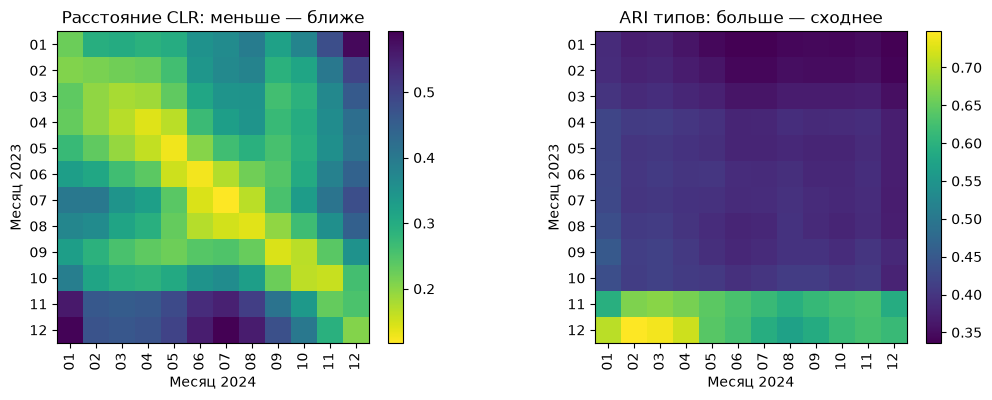

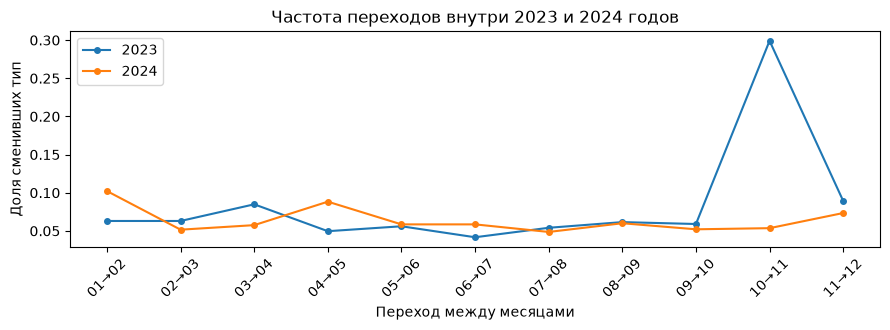

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
for ax, data, title, cmap in [
    (axes[0], clr_calendar, 'Расстояние CLR: меньше — ближе', 'viridis_r'),
    (axes[1], ari_calendar, 'ARI типов: больше — сходнее', 'viridis')
]:
    image = ax.imshow(data.to_numpy(float), aspect='equal', cmap=cmap)
    ax.set(title=title, xlabel='Месяц 2024', ylabel='Месяц 2023')
    ax.set_xticks(range(12), data.columns, rotation=90)
    ax.set_yticks(range(12), data.index)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
for year in (2023, 2024):
    ax.plot(yearly_switches['month_pair'], yearly_switches[f'switch_share_{year}'],
            marker='o', ms=4, label=str(year))
ax.set(xlabel='Переход между месяцами', ylabel='Доля сменивших тип',
       title='Частота переходов внутри 2023 и 2024 годов')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

### 7.1. Интерпретация календарного сравнения

На годоцентрированных CLR-признаках **совпадающие календарные месяцы двух лет оказываются наиболее близкими**: среднее расстояние равно 0,2095 против 0,3611 для пар различных месяцев. Нулевой сдвиг занимает первое место среди 12 циклических сопоставлений; для 99,21% муниципалитетов среднее расстояние совпадающих месяцев меньше среднего расстояния до других месяцев. Это свидетельствует о **повторяемости календарных колебаний потребительской структуры в 2023–2024 годах**.

По кластерным меткам результат другой: средний ARI одинаковых месяцев равен 0,4298, и это **не максимум** среди сдвигов (0,4351 при сдвиге 3). Частоты месячных переходов также воспроизводятся неполностью: для октября–ноября они составляют 29,91% в 2023 году и 5,36% в 2024 году. Повторяющиеся изменения расходов нельзя автоматически трактовать как повторяющиеся смены экономических типов.

Два года наблюдений не позволяют установить устойчивую многолетнюю сезонность или исключить влияние трендов и нерегулярных событий. Центрирование признаков по полному году используется **только для ретроспективной диагностики**, а не для построения графов и кластеризации на ранних датах.

## 8. Итоговые результаты и научное заключение

### 8.1. Вклад экономического графа

Для **2016 муниципалитетов за 24 месяца** выполнена контролируемая абляция графового коэффициента $\beta\in\{0;0{,}05;0{,}15;0{,}30\}$ при неизменных CLR-признаках, четырёх экономических типах, графе union kNN с $k=10$ и временной регуляризации $\lambda=0{,}25$. Конфигурация $\beta=0{,}15$ воспроизводит сохранённое разбиение этапа 11: минимальный по месяцам ARI равен **1,000**.

| Показатель | Без графового штрафа, $\beta=0$ | Итоговая модель, $\beta=0{,}15$ |
|---|---:|---:|
| Медианная модулярность $Q$ | 0,6363 | 0,6369 |
| Медианный ARI соседних месяцев | **0,8585** | 0,8480 |
| Медианная доля переходов | **5,65%** | 5,90% |
| Медианный SW, четыре контрольных месяца | 0,3028 | 0,3030 |
| Медианный CH, четыре контрольных месяца | 1576,6631 | 1577,2959 |

Относительно $\beta=0$ медианный ARI итоговой модели равен **0,9912**, NMI — **0,9835**, а медианная доля изменённых назначений — **0,32%**. Всего различаются **176 из 48 384** назначений «муниципалитет–месяц»; максимальная доля в отдельном месяце — 0,84%. При $\beta=0{,}30$ медианная доля отличий составляет 0,57%.

**Вывод:** графовая регуляризация оказывает измеримое, но малое влияние на разбиение; преимущество по модулярности не сопровождается ростом временной устойчивости или заметным улучшением геометрического качества. Граф построен из тех же CLR-признаков, поэтому не предоставляет независимого источника экономической информации. Значение $\beta=0{,}15$ сохраняется ради сопоставимости с исследованной экономической типологией, а $\beta=0$ остаётся содержательной абляционной альтернативой.

### 8.2. Устойчивость к случайной инициализации

По 72 сравнениям «пара random_state × месяц» медианные значения составляют **ARI = 0,9924** и **NMI = 0,9868**. Вместе с тем минимальные значения равны 0,4605 и 0,5731. Основной источник нестабильности — **декабрь 2023 года**: хотя бы два запуска дают разные назначения для **32,24%** муниципалитетов. В типе 3 доля таких объектов составляет 84,81%, в типе 0 — 23,07%.

Для декабря 2023 года простая гипотеза о близости всех неоднозначных объектов к границам CLR-кластеров недостаточна: в типе 3 медианный нормированный отрыв до центроидов у объектов с разными назначениями (0,5942) выше, чем у совпавших (0,2849). Причина локальной неустойчивости однозначно не установлена. При этом худший ARI в остальных четырёх выделенных месяцах составляет 0,9349–0,9596; **единичный проблемный месяц не опровергает высокую устойчивость большей части панели**.

### 8.3. Экономическая согласованность переходов

При $\beta=0{,}15$ медианная норма месячного изменения CLR-признаков для муниципалитетов, **сменивших тип**, равна **0,2415**, а для сохранивших тип — **0,1611**. Медианная доля перешедших муниципалитетов из верхнего квартиля CLR-изменений — 51,33% (при $\beta=0$ — 51,90%). Следовательно, переходы чаще сопровождаются заметными изменениями расходов, но **графовый штраф не усиливает это соответствие**. Причинная интерпретация этих наблюдений невозможна.

Ретроспективная проверка по восьми годовым характеристикам БДМО также не показывает заметного преимущества графового штрафа: медианная ранговая межгрупповая $\eta^2$ составляет **0,1298 против 0,1301** в декабре 2023 года и **0,1577 против 0,1578** в декабре 2024 года (соответственно $\beta=0$ и $\beta=0{,}15$). Расчёты выполнены по доступным значениям каждого показателя без замены пропусков нулями; годовые данные использованы только *ex post*.

### 8.4. Календарная повторяемость в 2023–2024 годах

Для проверки сезонных эффектов сопоставлены **годоцентрированные месячные CLR-векторы**, чтобы уменьшить влияние различий средних годовых уровней каждого муниципалитета. Получено:

| Показатель | Наблюдаемый результат |
|---|---:|
| Среднее CLR-расстояние одноимённых месяцев разных лет | **0,2095** |
| Среднее расстояние разных календарных месяцев | 0,3611 |
| Сокращение среднего расстояния для одноимённых месяцев | приблизительно **42%** |
| Доля муниципалитетов с меньшим расстоянием для одноимённых месяцев | **99,21%** |
| Ранг нулевого календарного сдвига по среднему расстоянию | **1 из 12** |
| Средний ARI разбиений одноимённых месяцев | 0,4298 |

**По исходным потребительским признакам календарная повторяемость за два наблюдаемых года выражена отчётливо.** Совпадающие месяцы оказываются ближе и в среднем по панели, и для подавляющего большинства муниципалитетов. Однако это описательный результат для двух лет, а не статистическое доказательство неизменной сезонности в будущем.

**По кластерным разбиениям аналогичной закономерности не обнаружено:** нулевой сдвиг не максимизирует средний ARI (при сдвиге на три месяца ARI равен 0,4351 против 0,4298 для нулевого), а сами значения ARI заметно ниже единицы. В частности, частота смены типа при переходе **октябрь → ноябрь** составляет **29,91% в 2023 году** и лишь **5,36% в 2024 году**. Следовательно, выделенные экономические типы не повторяют ежегодно один и тот же календарный сценарий переходов.

В рамках имеющихся данных можно утверждать **повторяемость относительных месячных отклонений структуры расходов**, но нельзя утверждать, что наблюдается столь же регулярная сезонная миграция между четырьмя типами. Нестабильность декабря 2023 года и резкий переход октября–ноября 2023 года нельзя объяснить только сезонностью: сопоставимого эффекта в 2024 году не установлено.

### 8.5. Окончательная конфигурация и границы результата

In [11]:
if acfg.get('save_enabled', False):
    if acfg.get('selection') not in ['retain_step11', 'revise_after_review']:
        raise ValueError('Не указан результат научной проверки graph_ablation_12.selection')
    output = ROOT / acfg['output_directory']
    output.mkdir(parents=True, exist_ok=True)
    target = output / 'ablation_diagnostics.parquet'
    comparison.to_parquet(target, index=False)
    print('Сохранена итоговая диагностика:', target.relative_to(ROOT))
else:
    print('Сохранение выключено до проверки результатов. Итоговые метки этапа 11 не изменяются.')

Сохранение выключено до проверки результатов. Итоговые метки этапа 11 не изменяются.
